# Laboratorio EIN092B — Visualización de series de tiempo

En este laboratorio se proporciona todo el código necesario. El trabajo consiste en ejecutar ejecutar cada celda, **observar** el gráfico y responder las preguntas. En algunos pasos se solicita cambiar un valor  y volver a ejecutar.

**Referencias:** S. Few, *Now You See It* (2009), análisis de series de tiempo; D. Wheeler, *Understanding Variation* (2000), gráficos XmR.


- Parte 1 | Variación a través del tiempo y gráficos de línea | CO₂ en Mauna Loa
- Parte 2 | Separar la señal del ruido: agregación y suavizado | CO₂ en Mauna Loa
- Parte 3 | Gráficos de control XmR | Caudal del río Nilo

## Preparación

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm

In [2]:
plt.rcParams.update({
    "figure.figsize": (11, 3.6), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8,
    "axes.edgecolor": "#888888", "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 1.4, "font.size": 10,
})
GRIS, AZUL, ROJO, NARANJA = "#7f7f7f", "#1f5fa8", "#c0392b", "#e08a1e"

### Datasets

- **CO₂ en Mauna Loa (Hawái):** Concentración atmosférica semanal de CO₂ en ppm, 1958–2001, medida por el programa de C. D. Keeling (Scripps). Tiene tendencia y un ciclo anual muy marcado.
- **Caudal anual del río Nilo en Asuán:** Volumen anual (10⁸ m³), 1871–1970. Es un conjunto clásico para estudiar cambios de nivel.

In [3]:
co2_sem = sm.datasets.co2.load_pandas().data["co2"].interpolate()    # semanal (rellena 59 semanas faltantes)
co2 = co2_sem.resample("MS").mean()                                  # promedio mensual

nilo = sm.datasets.nile.load_pandas().data
nilo = pd.Series(nilo["volume"].values, index=nilo["year"].astype(int), name="volumen")

print(co2_sem.head(3), "\n")
print(nilo.head(3))

1958-03-29    316.1
1958-04-05    317.3
1958-04-12    317.6
Freq: W-SAT, Name: co2, dtype: float64 

year
1871    1120.0
1872    1160.0
1873     963.0
Name: volumen, dtype: float64


## Parte 1: Variación a través del tiempo

Algunos estudios proponen observar una serie de tiempo buscando **patrones**: tendencia, variabilidad, tasa de cambio, covariación, ciclos y excepciones. El gráfico de línea es la forma natural de mostrarlos porque hace visible la forma del cambio. Como comparamos pendientes y no longitudes, el eje Y no necesita partir en cero.

### 1.1 — Exploración inicial

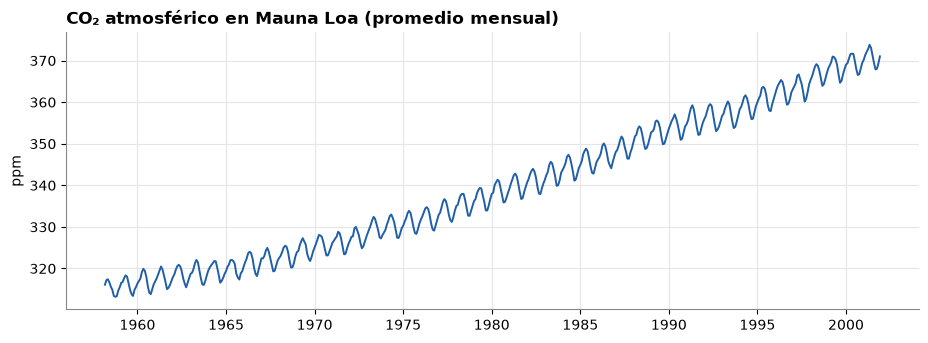

In [4]:
fig, ax = plt.subplots()
ax.plot(co2.index, co2, color=AZUL)
ax.set_title("CO₂ atmosférico en Mauna Loa (promedio mensual)")
ax.set_ylabel("ppm")
plt.show()

 **Pregunta 1.1:** ¿Qué patrones de la lista de Few reconoces a simple vista?

*Respuesta:*

Se reconocen varios de los patrones de Few:

- **Tendencia:** clara y creciente. El CO₂ pasa de ~315 ppm en 1958 a ~370 ppm en 2001.
- **Ciclo:** oscilación estacional anual muy regular, que se ve como un "dentado" repetido sobre la tendencia.
- **Variabilidad:** la amplitud del ciclo es bastante constante en el tiempo; hay poco ruido aleatorio.
- **Tasa de cambio:** la pendiente parece aumentar algo hacia el final (la curva se curva hacia arriba), aunque a simple vista cuesta cuantificarla (se ve en 1.4).
- **Excepciones:** no hay valores atípicos evidentes; la serie es muy "limpia".

### 1.2 — Relación de aspecto

La relación alto/ancho cambia cuánto “se ven” las pendientes. Cleveland mostró que las pendientes se comparan mejor cuando su orientación media ronda los 45°. La función siguiente calcula ese aspecto: normaliza cada pendiente por los rangos de los ejes y toma el inverso de la mediana.

Aspecto sugerido (alto/ancho): 0.22


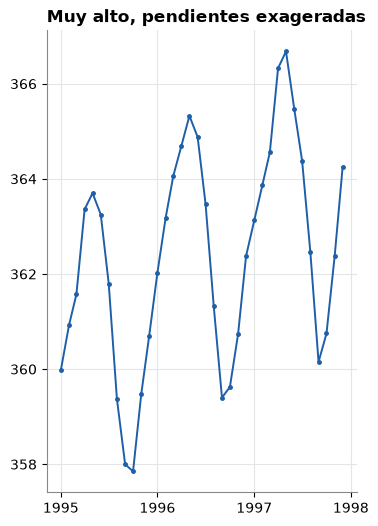

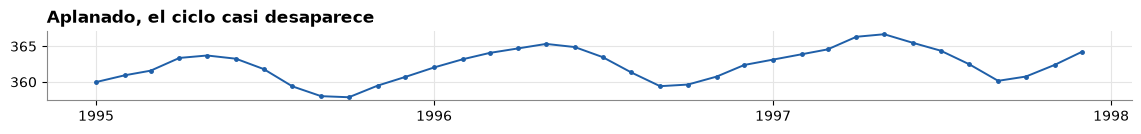

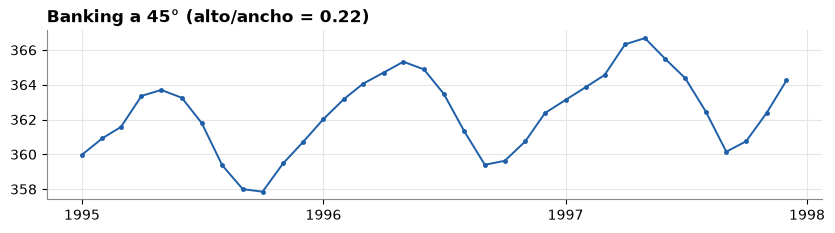

In [5]:
def aspecto_45(y):
    y = np.asarray(y, dtype=float)
    dy = np.diff(y) / (y.max() - y.min())
    dx = 1 / (len(y) - 1)
    s = np.abs(dy / dx)             #  s_plot = s*H/W
    return 1 / np.median(s[s > 0])  # np.meddian(s[s > 0]) es la pendiente mediana de la serie normalizada, y 1/s es el aspecto sugerido (alto/ancho) para un banking a 45°.
                                    # np.median(s)*H/W = 1, entonces H/W = 1/np.median(s)
tramo = co2["1995":"1997"]
alpha = aspecto_45(tramo.values)
print(f"Aspecto sugerido (alto/ancho): {alpha:.2f}")

for titulo, tam in [("Muy alto, pendientes exageradas", (4, 6)),
                    ("Aplanado, el ciclo casi desaparece", (14, 0.9)),
                    (f"Banking a 45° (alto/ancho = {alpha:.2f})", (10, 10 * alpha))]:
    fig, ax = plt.subplots(figsize=tam)
    ax.plot(tramo.index, tramo, color=AZUL, marker="o", ms=2.5)
    ax.set_title(titulo); ax.xaxis.set_major_locator(mdates.YearLocator())
    plt.show()

**Pregunta 1.2:** Los tres gráficos muestran exactamente los mismos datos. ¿Cómo exageran, esconden o mejoran la lectura del ciclo?

*Respuesta:*

- **Muy alto (4×6):** exagera las pendientes. Las subidas y bajadas del ciclo parecen casi verticales, lo que hace que el ciclo se vea más brusco de lo que es y dificulta comparar la inclinación de subidas vs. bajadas.
- **Aplanado (14×0.9):** esconde el ciclo. Las pendientes se aproximan a la horizontal y la serie parece casi una línea plana con pequeñas ondulaciones; se pierde el patrón estacional.
- **Banking a 45° (alto/ancho ≈ 0.22):** mejora la lectura. Las pendientes medias rondan 45°, por lo que se distingue bien la forma del ciclo (subida más lenta, bajada más rápida o viceversa) y se pueden comparar las inclinaciones sin distorsión.

Los tres gráficos tienen los mismos datos; solo cambia la relación de aspecto, y con ella lo que el ojo percibe.

### 1.3 — Separar ciclo y tendencia

Si superponemos todos los años, la tendencia desplaza cada curva hacia arriba y el ciclo queda oculto. El **cycle plot** dibuja, para cada mes, la sub-serie de ese mes a lo largo de los años (línea gris) y su promedio (línea azul). Primero quitamos la tendencia restando una media móvil centrada de 12 meses.

In [6]:
tendencia = co2.rolling(12, center=True).mean()  # devuelve un objeto de ventana móvil, lo que permite realizar agregaciones, transformaciones y otras operaciones sobre una ventana deslizante
tendencia.shape, co2.shape

((526,), (526,))

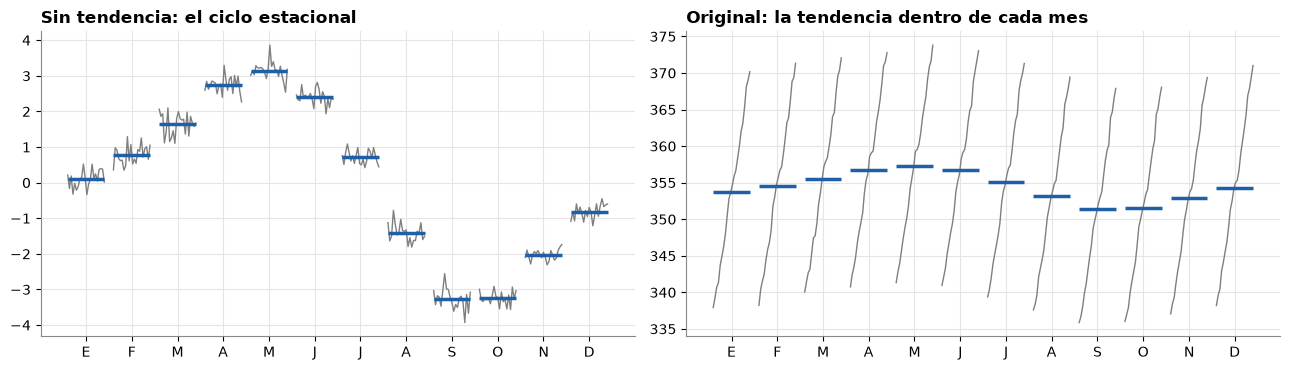

In [7]:
def cycle_plot(serie, ax, titulo=""):
    df = serie.to_frame("y")
    df["mes"] = df.index.month
    for m in range(1, 13):
        sub = df.loc[df["mes"] == m, "y"]
        x = np.linspace(m - 0.4, m + 0.4, len(sub))                   # cada mes ocupa su propio tramo del eje
        ax.plot(x, sub.values, color=GRIS, lw=1)                      # los años de ese mes
        ax.hlines(sub.mean(), m - 0.4, m + 0.4, color=AZUL, lw=2.5)   # promedio del mes
    ax.set_xticks(range(1, 13), ["E","F","M","A","M","J","J","A","S","O","N","D"])
    ax.set_title(titulo)

sin_tendencia = (co2 - tendencia)["1980":"2001"].dropna()

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
cycle_plot(sin_tendencia, axs[0], "Sin tendencia: el ciclo estacional")
cycle_plot(co2["1980":"2001"], axs[1], "Original: la tendencia dentro de cada mes")
plt.tight_layout(); plt.show()

**Pregunta 1.3:** ¿En qué mes el CO₂ llega a su máximo y en cuál a su mínimo? ¿Qué muestra la pendiente de cada línea gris en el panel derecho?

*Respuesta:*

- **Máximo:** mayo (~+3 ppm sobre la tendencia), cuando termina el invierno boreal y la vegetación del hemisferio norte aún no ha comenzado a absorber CO₂ de forma masiva.
- **Mínimo:** septiembre–octubre (~-3.3 ppm), tras el crecimiento de verano, cuando la fotosíntesis ha retirado CO₂ de la atmósfera.

En el panel derecho, cada línea gris es la evolución de un mismo mes a lo largo de los años. Todas tienen **pendiente positiva y bastante similar**: eso muestra que la tendencia creciente (~35 ppm entre 1980 y 2001) afecta a todos los meses por igual. Es decir, la tendencia domina sobre el ciclo en el gráfico original, y por eso hay que quitarla para ver la estacionalidad.

### 1.4 — Tasa de cambio

El gráfico anterior muestra que el CO₂ sube, pero no si sube cada vez más rápido. Para ver la tasa de cambio graficamos la diferencia respecto al mismo mes del año anterior (eso además elimina el ciclo anual).

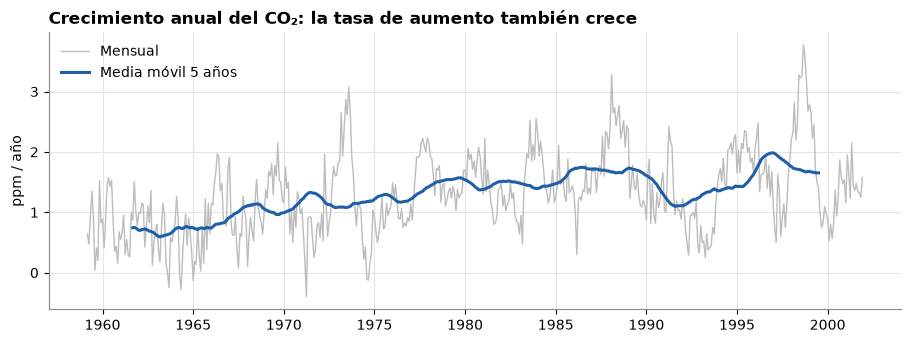

In [8]:
crec = co2.diff(12)   # ppm ganadas respecto al mismo mes del año anterior

fig, ax = plt.subplots()
ax.plot(crec.index, crec, color="#bdbdbd", lw=1, label="Mensual")
ax.plot(crec.rolling(60, center=True).mean(), color=AZUL, lw=2.2, label="Media móvil 5 años")
ax.set_title("Crecimiento anual del CO₂: la tasa de aumento también crece")
ax.set_ylabel("ppm / año"); ax.legend(frameon=False, loc="upper left")
plt.show()

**Pregunta 1.4:** ¿Cuántas ppm por año aumentaba el CO₂ en los años 60 y cuántas en los 90? ¿Por qué esto no se aprecia bien en el gráfico del punto 1.1?

*Respuesta:*

- **Años 60:** aproximadamente **0.7–1 ppm/año** (la media móvil de 5 años parte en ~0.7 y sube a ~1.1 hacia fines de la década).
- **Años 90:** aproximadamente **1.5 ppm/año** en promedio (con oscilaciones entre ~1.1 en 1992 y ~2 en 1997), es decir, **más del doble** que en los 60.

En el gráfico 1.1 no se aprecia bien porque ahí se ve el **nivel** (la serie acumulada) y no su **derivada**. Una curva levemente convexa es difícil de distinguir de una recta a simple vista, y además el ciclo estacional de ±3 ppm tapa diferencias de pocas décimas por año. Al graficar la diferencia interanual, la tasa de cambio pasa a ser la variable que se ve directamente.

## Parte 2: Separar la señal del ruido

Toda serie mezcla señal (tendencia, ciclos, cambios reales) y ruido (variación aleatoria). Usamos dos herramientas:
- **Agregación:** Cambiar la granularidad (semana → mes → año). Elimina los ciclos más cortos que el intervalo, pero también puede ocultar detalles.
- **Suavizado:** Medias móviles que conservan la resolución temporal. El tamaño de la ventana decide qué se considera ruido.

Regla general: Mostrar el dato crudo de manera tenue y destacar la señal.

### 2.1 — Agregación

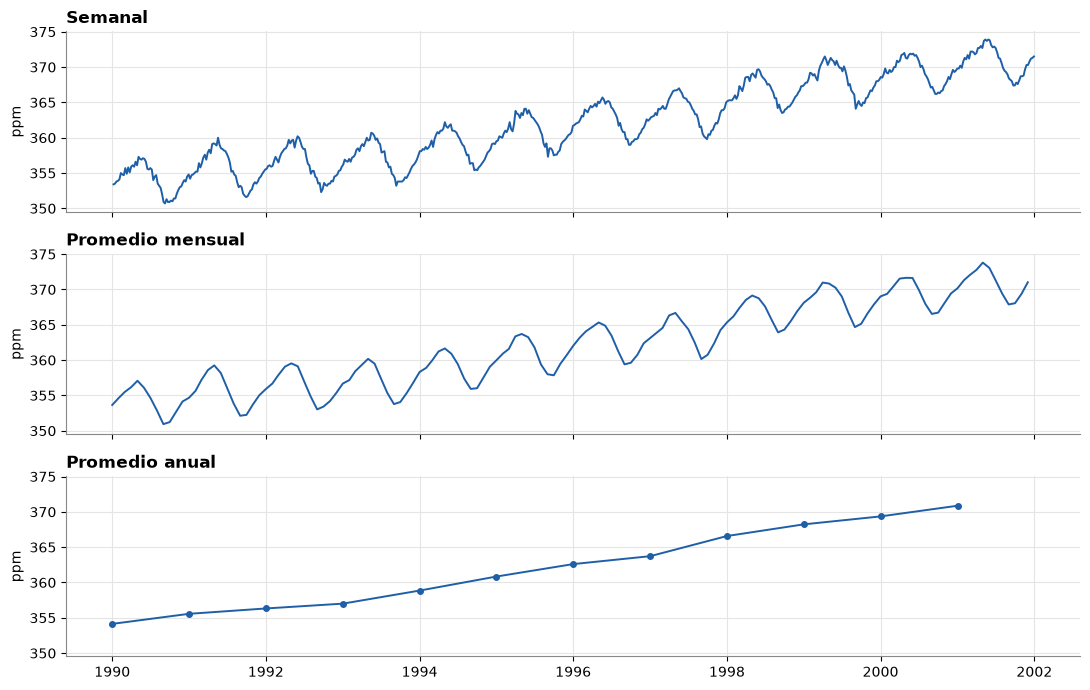

In [9]:
tramo = co2_sem["1990":"2001"]

fig, axs = plt.subplots(3, 1, figsize=(11, 7), sharex=True, sharey=True)
for ax, (regla, nombre) in zip(axs, [("W", "Semanal"), ("MS", "Promedio mensual"), ("YS", "Promedio anual")]):
    serie = tramo.resample(regla).mean()
    ax.plot(serie.index, serie, color=AZUL, marker="o" if regla == "YS" else None, ms=4)
    ax.set_title(nombre); ax.set_ylabel("ppm")
plt.tight_layout(); plt.show()

**Pregunta 2.1:** ¿Desaparecen ciertos patrones al llevar a cabo la agregación? ¿Para qué pregunta sería adecuado cada nivel?

*Respuesta:*

Sí, desaparecen patrones al agregar:

- **Semanal:** muestra el ciclo estacional, la variabilidad semana a semana y los pequeños saltos o excepciones. Adecuado para estudiar el detalle del ciclo anual o detectar anomalías puntuales.
- **Promedio mensual:** conserva el ciclo anual con menos ruido. Adecuado para estudiar la estacionalidad (meses de máximo y mínimo) y comparar años entre sí.
- **Promedio anual:** el ciclo **desaparece por completo** (se promedia sobre un ciclo completo) y solo queda la tendencia. Adecuado para preguntas de largo plazo: cuánto crece el CO₂ por década o si la tasa de crecimiento cambia.

Agregar elimina ciclos más cortos que el intervalo, pero también oculta información; el nivel correcto depende de la pregunta.

### 2.2 — Suavizado con medias móviles

Dibujamos el dato semanal en gris y encima dos medias móviles centradas. Iteramos sobre diferentes ventanas.

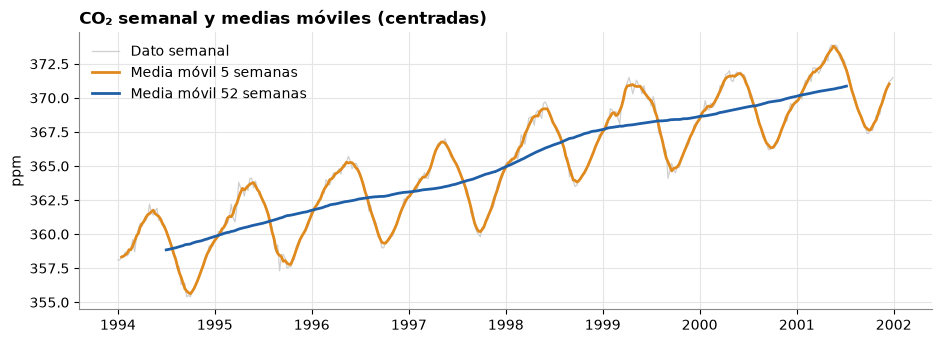

In [10]:
centrada = True          # <- cambia a False y vuelve a ejecutar
ventanas = [5, 52]       # <- prueba también otras ventanas, por ejemplo [13, 104]

tramo = co2_sem["1994":"2001"]
fig, ax = plt.subplots()
ax.plot(tramo.index, tramo, color="#cfcfcf", lw=0.9, label="Dato semanal")
for w, color in zip(ventanas, [NARANJA, AZUL]):
    ax.plot(tramo.rolling(w, center=centrada).mean(), color=color, lw=2, label=f"Media móvil {w} semanas")
ax.set_title(f"CO₂ semanal y medias móviles ({'centradas' if centrada else 'no centradas'})")
ax.set_ylabel("ppm"); ax.legend(frameon=False, loc="upper left")
plt.show()

**Pregunta 2.2:** ¿Qué elimina la ventana de 5 semanas y qué elimina la de 52? ¿Qué ocurre con los máximos y mínimos cuando la media móvil no es centrada?

*Respuesta:*

- **Ventana de 5 semanas:** elimina el ruido de muy corto plazo (variación semana a semana), pero conserva el ciclo estacional anual, por lo que la curva sigue ondulando.
- **Ventana de 52 semanas:** abarca un ciclo anual completo, por lo que **elimina el ciclo estacional** y deja solo la tendencia (una curva casi recta y creciente).

**Con media móvil no centrada** (solo datos pasados), el valor suavizado se asigna al final de la ventana, por lo que la curva queda **desfasada/retrasada**: los máximos y mínimos aparecen más tarde que en los datos reales (aprox. media ventana de retraso), y con la ventana larga el desfase es mayor. La centrada alinea los picos con los datos, pero pierde valores en los extremos y usa información futura.

## Parte 3: Gráficos de control XmR

### 3.1 — Datos del Nilo

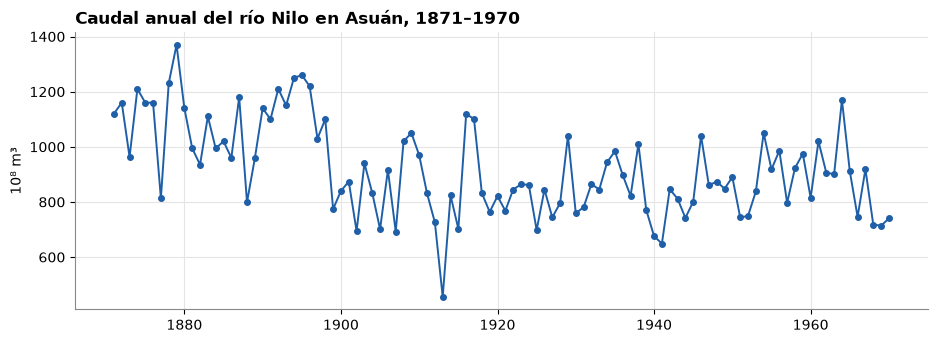

In [11]:
fig, ax = plt.subplots()
ax.plot(nilo.index, nilo, color=AZUL, marker=".", ms=8)
ax.set_title("Caudal anual del río Nilo en Asuán, 1871–1970")
ax.set_ylabel("10⁸ m³")
plt.show()

**Pregunta 3.1:** Solo mirando el gráfico, ¿dirías que el caudal se mantiene estable? ¿Ves algún momento en que cambie su comportamiento?

*Respuesta:*

No, el caudal **no parece estable**. Hasta ~1900 oscila alrededor de 1100 (10⁸ m³), con valores frecuentes sobre 1200. Cerca de **1898–1900 hay una caída** y desde entonces la serie oscila a un nivel menor (~850), con un mínimo muy bajo en 1913. Parece haber un **cambio de nivel** hacia comienzos del siglo XX (documentado, se atribuye a cambios climáticos y a la construcción de la primera presa de Asuán, 1902), aunque a ojo cuesta saber si es cambio real o variación natural, y eso es lo que resuelve el XmR.

### 3.2 — Construir el XmR

Calculamos los límites con un **periodo base** que consideramos estable: los primeros 27 años (1871–1897). Luego extendemos esos límites al resto de la serie.

{'Xbar': 1097.7, 'mRbar': 143.9, 'UNPL': 1480.5, 'LNPL': 714.8, 'URL': 470.3}


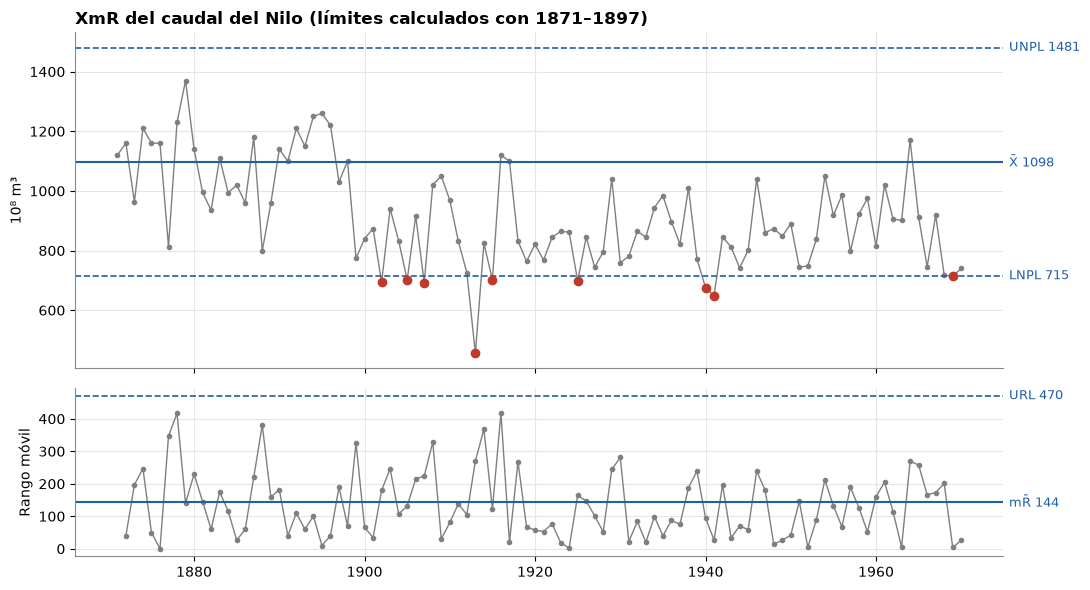

Años fuera de los límites naturales: 9


In [12]:
def xmr_limites(x):
    x = np.asarray(x, dtype=float)
    mr = np.abs(np.diff(x))
    Xbar, mRbar = x.mean(), mr.mean()
    return {"Xbar": Xbar, "mRbar": mRbar,
            "UNPL": Xbar + 2.66 * mRbar, "LNPL": Xbar - 2.66 * mRbar, "URL": 3.268 * mRbar}

def _etiqueta(ax, y, texto):
    ax.annotate(f"{texto} {y:.0f}", xy=(1.0, y), xycoords=("axes fraction", "data"),
                xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=AZUL)

def grafico_xmr(serie, lim, titulo="", unidad=""):
    mr = serie.diff().abs()
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True,
                                   gridspec_kw={"height_ratios": [2, 1]})
    # Gráfico X
    ax1.plot(serie.index, serie, color=GRIS, marker="o", ms=3, lw=1)
    ax1.axhline(lim["Xbar"], color=AZUL, lw=1.5); _etiqueta(ax1, lim["Xbar"], "X̄")
    for k in ("UNPL", "LNPL"):
        ax1.axhline(lim[k], color=AZUL, lw=1.2, ls="--"); _etiqueta(ax1, lim[k], k)
    fuera = serie[(serie > lim["UNPL"]) | (serie < lim["LNPL"])]
    ax1.plot(fuera.index, fuera, "o", color=ROJO, ms=6, zorder=3)
    ax1.set_title(titulo); ax1.set_ylabel(unidad)
    # Gráfico mR
    ax2.plot(mr.index, mr, color=GRIS, marker="o", ms=3, lw=1)
    ax2.axhline(lim["mRbar"], color=AZUL, lw=1.5); _etiqueta(ax2, lim["mRbar"], "mR̄")
    ax2.axhline(lim["URL"], color=AZUL, lw=1.2, ls="--"); _etiqueta(ax2, lim["URL"], "URL")
    alto = mr[mr > lim["URL"]]
    ax2.plot(alto.index, alto, "o", color=ROJO, ms=6, zorder=3)
    ax2.set_ylabel("Rango móvil")
    plt.tight_layout(); plt.show()
    return len(fuera)

lim = xmr_limites(nilo.loc[1871:1897])
print({k: round(float(v), 1) for k, v in lim.items()})
n = grafico_xmr(nilo, lim, "XmR del caudal del Nilo (límites calculados con 1871–1897)", "10⁸ m³")
print(f"Años fuera de los límites naturales: {n}")

**Pregunta 3.2** ¿A partir de qué año empiezan a aparecer puntos fuera de los límites? ¿Están arriba o abajo? ¿Qué dice eso sobre el río?

*Respuesta:*

Los puntos fuera de los límites empiezan a aparecer en **1902** (luego 1905, 1907, 1913, 1915, 1925, 1940, 1941 y 1969; 9 en total). **Todos están por debajo del límite inferior natural (LNPL ≈ 715)**; ninguno supera el límite superior.

Esto indica que el río cambió de régimen: el proceso que generó los datos de 1871–1897 ya no es el mismo. El caudal bajó de forma sistemática y no por simple variación aleatoria, lo que es consistente con la construcción de la presa de Asuán en 1902 y/o un cambio climático. Que los puntos fuera de límites sean casi todos bajos confirma un descenso del nivel medio, y no ruido.

### 3.3 — Importancia del periodo base

Ahora los límites se calculan con todos los años. Ejecuta y compara con los resultados del punto 3.2.

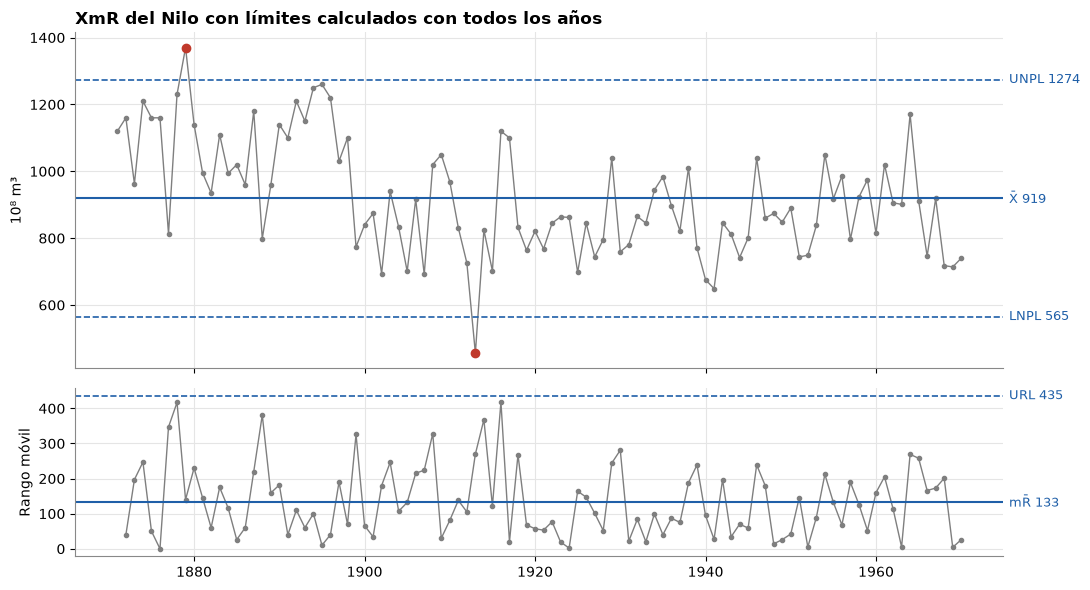

Años fuera de los límites naturales: 2


In [13]:
periodo_base = nilo.loc[1871:1970]     # <- compara con nilo.loc[1871:1897]
lim_todo = xmr_limites(periodo_base)
n = grafico_xmr(nilo, lim_todo, "XmR del Nilo con límites calculados con todos los años", "10⁸ m³")
print(f"Años fuera de los límites naturales: {n}")

**Pregunta 3.3** ¿Qué pasó con las señales? ¿Por qué calcular los límites incluyendo el periodo posterior al cambio las esconde?

*Respuesta:*

Las señales **casi desaparecen**: se pasa de 9 puntos fuera de los límites a solo 2 (1879 por arriba y 1913 por abajo). La media baja a ~919 y los límites se ensanchan (715–1481 pasan a 565–1274), con lo cual los valores bajos posteriores a 1900 caen dentro de los límites.

Al incluir datos posteriores al cambio, el periodo base mezcla dos regímenes distintos. Eso desplaza la media hacia un valor intermedio que no representa a ninguno, e **infla la variabilidad** (mR̄ y límites), de modo que el cambio de nivel queda "absorbido" como si fuera variación normal y el gráfico deja de detectarlo. Por eso el periodo base debe corresponder a un periodo estable, anterior al cambio que se quiere detectar.